# 2D views + 3D graph: the whole flow, step by step

This notebook follows **one real MFCAD++ test part** through every step, then shows how the three models trained and scored.

```
STEP file
  -> step 0  number the faces (same numbers for 3D and 2D)
  -> step 1  3D: 15 numbers per face + which faces touch + true label      (train_mfcad.py)
  -> step 2  2D: 14 grey pictures + 14 face-id maps                         (render_views.py)
  -> step 3  2D: SigLIP2 describes every 16 x 16 square with 768 numbers    (vlm_features.py)
  -> step 4  2D: smooth those to 4 x 4 pixel cells, average the cells under
                 each face -> 769 numbers / face                            (vlm_features.py)
  -> step 5  join 3D + 2D for every face                                    (train_fused.py)
  -> step 6  train 3 models: 3D only / 2D only / both, 3 runs each          (train_fused.py)
  -> step 7  test on 1500 new parts                                         (train_fused.py)
```

**Before running:** `python views2d/train_fused.py` must have been run once (it writes `views2d/data/fused_results.pt`).
Then **Run All**. Nothing here trains a model; it only reads the saved results (about 1 minute).

Sections:
1. Setup
2. The part we follow (steps 0-1)
3. Its 14 pictures (step 2)
4. The face-id map, up close
5. From squares to one vector per face (steps 3-4)
6. What the face vectors look like
7. How many faces can the pictures see?
8. Training curves: loss and validation accuracy (step 6)
9. Test results (step 7)
10. Accuracy per class
11. Seen vs hidden faces
12. Part viewer: right and wrong faces, per model
13. Before vs after the fixes (version 1 -> version 2)

In [1]:
import os, sys
HERE = os.getcwd()                                         # this notebook's folder: brep_gnn/views2d
sys.path.insert(0, HERE)
sys.path.insert(0, os.path.dirname(HERE))                  # brep_gnn/  (shared code)
sys.path.insert(0, os.path.join(os.path.dirname(HERE), "mfcad"))

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from torch_geometric.loader import DataLoader

from brep_to_graph import step_to_graph
from gnn_common import accuracy, mean_iou
from render_views import ISO, VIEWS, false_colour, render_part, visible_faces
from train_fused import attach, build_model
from train_mfcad import LABELS, load_split, split_files
from vlm_features import GRID, PATCH, POOL, build_split

%matplotlib inline

K = len(LABELS)
STOCK = LABELS.index("Stock")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# chart style: light surface, quiet axes, one fixed colour per model
SURFACE, INK, INK2, MUTED, GRIDLINE, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODELS = ["3D only (GNN)", "2D only (each face alone)", "fused 2D + 3D (GNN)"]
SHORT = dict(zip(MODELS, ["3D only", "2D only", "2D + 3D"]))
COLOUR = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a"]))
GOOD, BAD, HIGHLIGHT = "#0ca30c", "#d03b3b", "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRIDLINE,
    "grid.linewidth": 0.8, "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})


def short_label(c, n=24):
    name = LABELS[c]
    return name if len(name) <= n else name[:n - 1] + "."


def no_axes(axes):
    for ax in np.ravel(axes):
        ax.axis("off")

C:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
N_TEST = 1500
folder, test_files = split_files("test", N_TEST)        # same 1500 parts, same order, as training used
test_graphs = load_split("test", N_TEST)                 # 3D: x, edges, y      (mfcad/data/mfcad_cache)
test_feats = build_split("test", N_TEST)                 # 2D: 769 numbers/face (views2d/data/feature_cache)
results = torch.load(os.path.join(HERE, "data", "fused_results.pt"), weights_only=False)
assert len(test_graphs) == len(test_feats) == len(test_files)

attach(test_graphs, test_feats, results["vis_mean"], results["vis_std"])   # step 5: graph.v = 2D numbers
RUNS = results["runs"]                                   # each model was trained len(RUNS) times
print(f"{len(test_graphs)} test parts, {sum(g.num_nodes for g in test_graphs)} faces, {len(RUNS)} training runs saved")
print("each graph now holds:", {k: tuple(v.shape) for k, v in test_graphs[0].items()})

1500 test parts, 44631 faces, 3 training runs saved
each graph now holds: {'x': (23, 15), 'edge_index': (2, 108), 'edge_attr': (108, 5), 'y': (23,), 'v': (23, 769)}


## 2. The part we follow (steps 0-1)

We pick the first test part with 15-40 faces and at least 3 different machining features (change `PART` to look at any other part, 0-1499).

The table is the **3D side**: every face gets a number (step 0), its shape is read (step 1) and its true label comes from the face name stored inside the STEP file.

In [3]:
def pick_part():
    for i, g in enumerate(test_graphs):
        if 15 <= g.num_nodes <= 40 and len(set(g.y.tolist()) - {STOCK}) >= 3:
            return i


PART = pick_part()
path = os.path.join(folder, test_files[PART])
G = step_to_graph(path)
g = test_graphs[PART]
assert G.number_of_nodes() == g.num_nodes

print(f"part {PART}: {test_files[PART]}  ->  {g.num_nodes} faces, {G.number_of_edges()} links between faces\n")
print(f"{'node':>4}  {'surface':<9}{'area mm2':>9}   true label")
for i in range(g.num_nodes):
    n = G.nodes[i]
    print(f"{i:>4}  {n['type']:<9}{n['area']:>9.1f}   {LABELS[g.y[i]]}")

part 0: 4797.step  ->  23 faces, 54 links between faces

node  surface   area mm2   true label
   0  plane        294.0   Stock
   1  cone          10.9   Chamfer
   2  plane        109.8   Stock
   3  plane        272.2   Stock
   4  plane        267.8   Stock
   5  plane        132.2   Stock
   6  plane          6.1   Circular end pocket
   7  cylinder      13.0   Circular end pocket
   8  plane          6.1   Circular end pocket
   9  cylinder      13.0   Circular end pocket
  10  cylinder      56.2   Through hole
  11  plane        278.9   Rectangular through step
  12  plane         25.6   Stock
  13  plane         22.4   Rectangular through step
  14  plane         20.9   Triangular passage
  15  plane         16.0   Triangular passage
  16  plane         20.5   Triangular passage
  17  plane          9.3   Circular end pocket
  18  cylinder      26.6   Circular end pocket
  19  plane          9.3   Circular end pocket
  20  cylinder      26.6   Circular end pocket
  21  plane   

## 3. Its 14 pictures (step 2)

`render_views.render_part` photographs the part from 14 directions: the 6 straight views (front, back, top, bottom, right, left)
and 8 corner views that look into pockets, slots and holes at an angle. For every view there are three pictures
(the corner views below show only the first two, to keep the page short):

- **row 1, grey picture**: what it looks like. This is what SigLIP2 reads.
- **row 2, face-id map**: every pixel holds the number of the face seen there. Shown in random colours, with the node number written on each face.
- **row 3, line drawing**: an engineering-style drawing, hidden edges dashed. Not used for training yet.

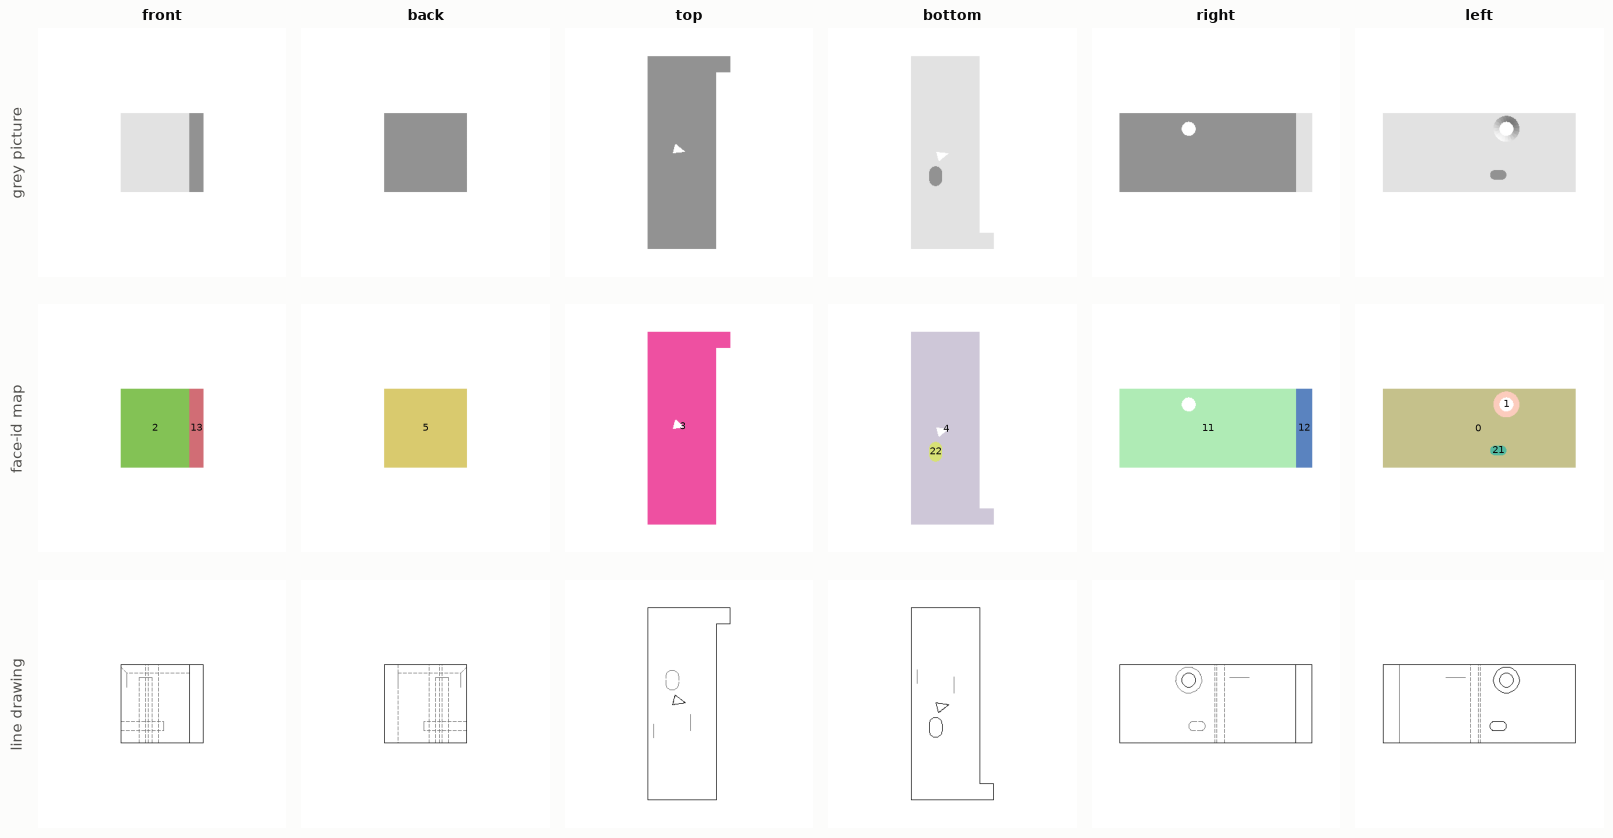

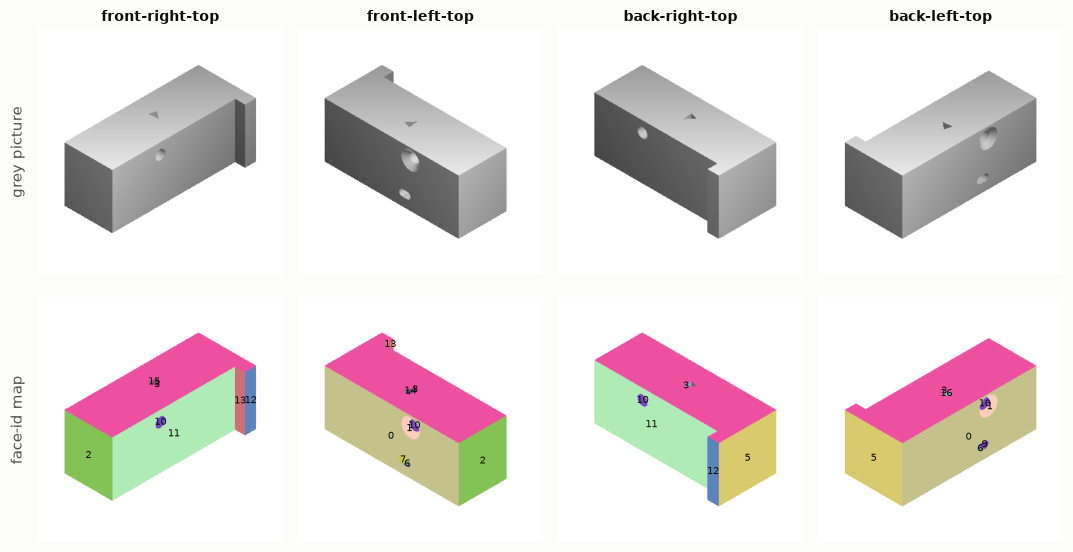

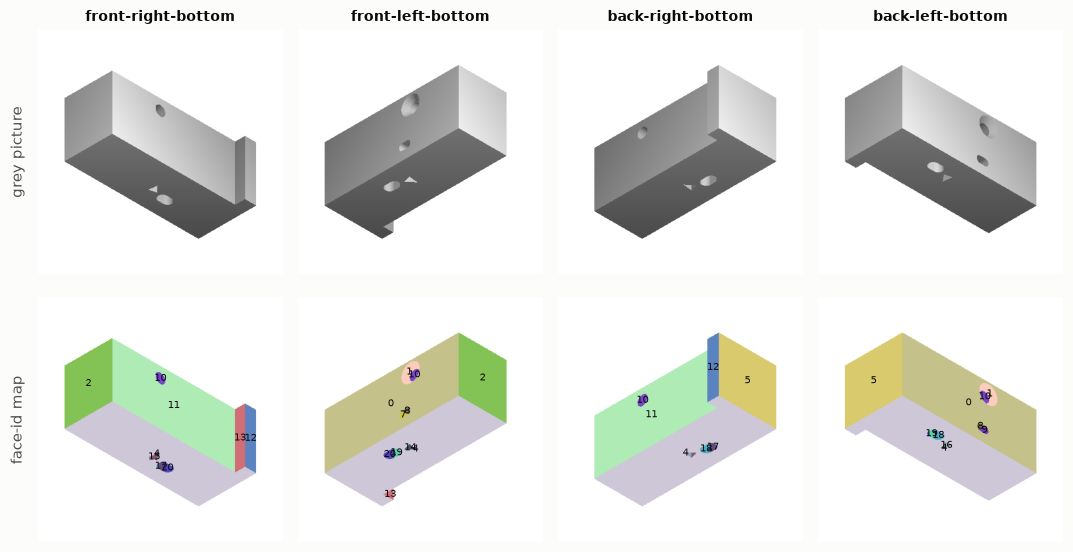

In [4]:
r = render_part(path)
names = list(VIEWS)


def sheet(view_names, rows=("grey picture", "face-id map", "line drawing")):
    fig, axes = plt.subplots(len(rows), len(view_names), figsize=(2.7 * len(view_names), 2.9 * len(rows)))
    for c, name in enumerate(view_names):
        j = names.index(name)
        fid = r["face_id"][j]
        pics = {"grey picture": r["shaded"][j], "face-id map": false_colour(fid), "line drawing": r["drawing"][j]}
        for row, kind in enumerate(rows):
            ax = axes[row, c]
            ax.imshow(pics[kind], cmap="gray" if kind == "line drawing" else None, vmin=0, vmax=255)
            if kind == "face-id map":
                for k in visible_faces(fid):
                    ys, xs = np.nonzero(fid == k)
                    if len(xs) > 60:
                        ax.text(xs.mean(), ys.mean(), str(k - 1), fontsize=7, ha="center", va="center")
        axes[0, c].set_title(name, loc="center", fontsize=10)
    for row, label in enumerate(rows):
        axes[row, 0].text(-20, 192, label, rotation=90, ha="right", va="center", color=INK2, fontsize=11)
    no_axes(axes)
    fig.tight_layout()
    plt.show()


straight, corners = names[:6], names[6:]
sheet(straight)
sheet(corners[:4], rows=("grey picture", "face-id map"))
sheet(corners[4:], rows=("grey picture", "face-id map"))

## 4. The face-id map, up close

The face-id map is **the same size as the picture** (384 x 384), but each pixel holds a **face number** instead of a grey value.
In the file a pixel holds `node + 1` so that `0` can mean "nothing here"; below we print the node number directly.

We pick one interesting face (the biggest non-Stock face seen in the iso view) and follow it through the next steps.

In [5]:
J_ISO = names.index(ISO)                                # the usual iso view: front-right-top
fid = r["face_id"][J_ISO]
candidates = [k - 1 for k in visible_faces(fid) if g.y[k - 1] != STOCK]
FACE = max(candidates, key=lambda i: (fid == i + 1).sum())
print(f"face we follow: node {FACE} = {G.nodes[FACE]['type']}, true label '{LABELS[g.y[FACE]]}'")
print(f"its pixels in the iso view: {(fid == FACE + 1).sum()}\n")

print("the iso face-id map, every 12th pixel (32 x 32 of the 384 x 384); '.' = background")
for row in fid[6::12, 6::12]:
    print(" ".join(" ." if x == 0 else f"{x - 1:2d}" for x in row))

face we follow: node 11 = plane, true label 'Rectangular through step'
its pixels in the iso view: 18818

the iso face-id map, every 12th pixel (32 x 32 of the 384 x 384); '.' = background
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  3  3  3  3  .  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  3  3  3  3  3  3  .  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  3  3  3  3  3  3  3  3  3  3  .  .  .  .  .  .
 .  .  .  .  .  .  .  .  .  .  .  .  .  .  

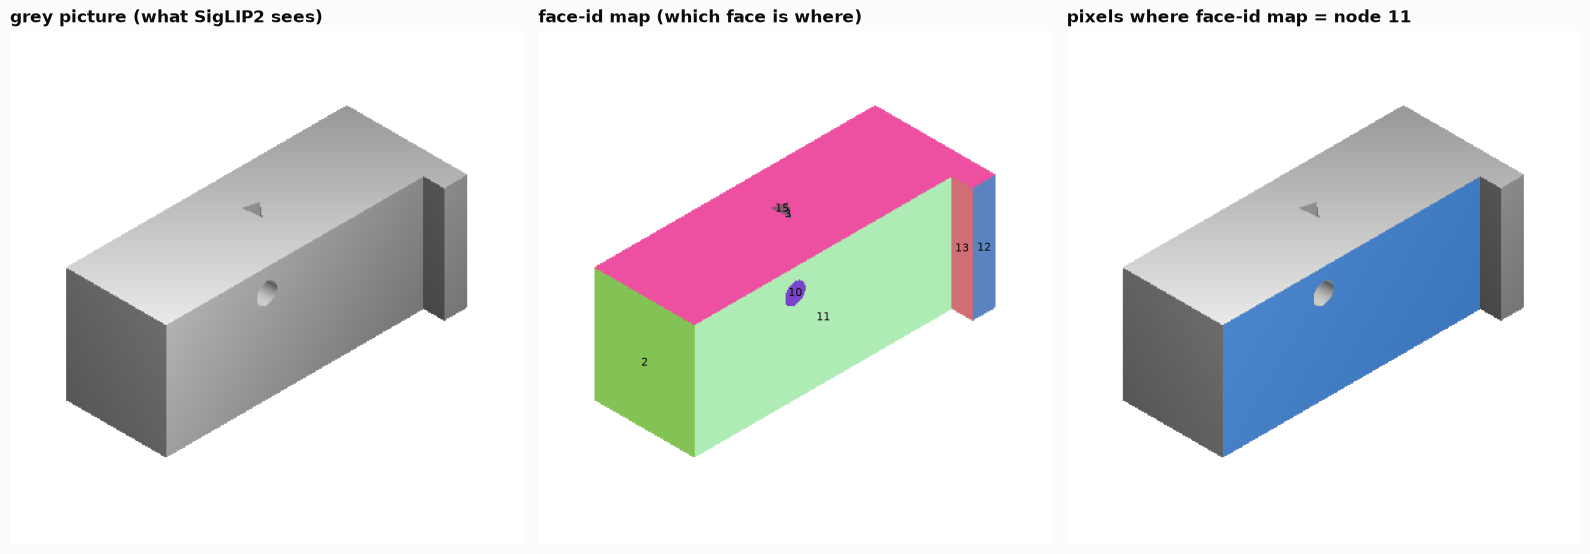

In [6]:
mask = fid == FACE + 1
overlay = np.zeros((*mask.shape, 4))
overlay[mask] = (0.16, 0.47, 0.84, 0.75)                   # HIGHLIGHT blue, mostly opaque

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(r["shaded"][J_ISO])
axes[0].set_title("grey picture (what SigLIP2 sees)")
axes[1].imshow(false_colour(fid))
for k in visible_faces(fid):
    ys, xs = np.nonzero(fid == k)
    if len(xs) > 60:
        axes[1].text(xs.mean(), ys.mean(), str(k - 1), fontsize=8, ha="center", va="center")
axes[1].set_title("face-id map (which face is where)")
axes[2].imshow(r["shaded"][J_ISO])
axes[2].imshow(overlay)
axes[2].set_title(f"pixels where face-id map = node {FACE}")
no_axes(axes)
fig.tight_layout()
plt.show()

## 5. From squares to one vector per face (steps 3-4)

**Step 3.** SigLIP2 cuts each 384 x 384 picture into a **24 x 24 grid of squares** (16 x 16 pixels each) and describes every square with 768 numbers.

**Step 4.** The face-id map tells us which squares the face lies in, and how many of its pixels fall in each.
The face's vector is the **average of those squares' 768 numbers**, weighted by those pixel counts, over all 14 views.
Squares the face fills completely count most; squares it only touches count little.

(Version 2 detail: before averaging, the 24 x 24 grid of square vectors is smoothly enlarged to 96 x 96 cells of 4 x 4 pixels,
and the averaging uses those cells. Same idea as below, just finer, so two tiny faces in the same 16 x 16 square
still get different vectors.)

Below: the grid on the iso picture, zoomed to the face. The darker a square, the more of the face's pixels it holds (the number in it).

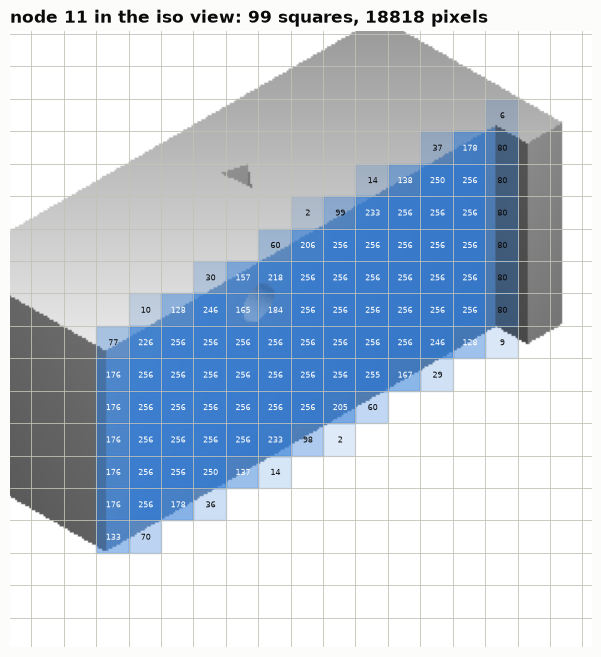

the same face in every view (all of these squares are averaged together):
  front                   0 pixels in   0 squares   not seen
  back                    0 pixels in   0 squares   not seen
  top                     0 pixels in   0 squares   not seen
  bottom                  0 pixels in   0 squares   not seen
  right               32937 pixels in 144 squares    31.2% of the weight
  left                    0 pixels in   0 squares   not seen
  front-right-top     18818 pixels in  99 squares    17.8% of the weight
  front-left-top          0 pixels in   0 squares   not seen
  back-right-top      17473 pixels in  93 squares    16.6% of the weight
  back-left-top           0 pixels in   0 squares   not seen
  front-right-bottom  18818 pixels in  99 squares    17.8% of the weight
  front-left-bottom       0 pixels in   0 squares   not seen
  back-right-bottom   17473 pixels in  93 squares    16.6% of the weight
  back-left-bottom        0 pixels in   0 squares   not seen


In [7]:
weights = mask.reshape(GRID, PATCH, GRID, PATCH).sum(axis=(1, 3))      # face pixels in each 16 x 16 square
ys, xs = np.nonzero(mask)
pad = 3 * PATCH

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(r["shaded"][J_ISO])
ax.imshow(overlay, alpha=0.5)
for p in range(0, 385, PATCH):
    ax.axhline(p - 0.5, color=AXIS, linewidth=0.6)
    ax.axvline(p - 0.5, color=AXIS, linewidth=0.6)
for gy, gx in zip(*np.nonzero(weights)):
    w = weights[gy, gx]
    ax.add_patch(Rectangle((gx * PATCH - 0.5, gy * PATCH - 0.5), PATCH, PATCH, facecolor=HIGHLIGHT,
                           alpha=0.15 + 0.6 * w / PATCH ** 2, edgecolor=HIGHLIGHT, linewidth=1))
    ax.text(gx * PATCH + PATCH / 2, gy * PATCH + PATCH / 2, str(w), ha="center", va="center", fontsize=6,
            color="#ffffff" if w > 120 else INK)
ax.set_xlim(max(xs.min() - pad, 0), min(xs.max() + pad, 384))
ax.set_ylim(min(ys.max() + pad, 384), max(ys.min() - pad, 0))
ax.set_title(f"node {FACE} in the iso view: {int((weights > 0).sum())} squares, {int(mask.sum())} pixels")
ax.axis("off")
plt.show()

print("the same face in every view (all of these squares are averaged together):")
total = sum(int((r["face_id"][j] == FACE + 1).sum()) for j in range(len(names)))
for j, name in enumerate(names):
    m = r["face_id"][j] == FACE + 1
    sq = int((m.reshape(GRID, PATCH, GRID, PATCH).sum(axis=(1, 3)) > 0).sum())
    share = f"{100 * m.sum() / total:5.1f}% of the weight" if m.any() else "not seen"
    print(f"  {name:<18} {int(m.sum()):6d} pixels in {sq:3d} squares   {share}")

## 6. What the face vectors look like

Each face of the part now has a **visual vector `v`**: 768 numbers + a flag (1 = seen in some view). We can't read 768 numbers, but we can compare faces:
**cosine similarity** is close to +1 when two faces look alike to SigLIP2 and near 0 or below when they don't.

Faces are sorted by their true label. If the pictures carry useful information, faces with the **same label** should form bright blocks along the diagonal.
Faces no view sees are left out (their vector is all zeros).

Version 1 averaged over whole 16 x 16 squares, so tiny faces sharing a square (for example two walls of a small passage) got
exactly the same vector. Version 2 averages over 4 x 4 pixel cells, so such faces now differ somewhat.

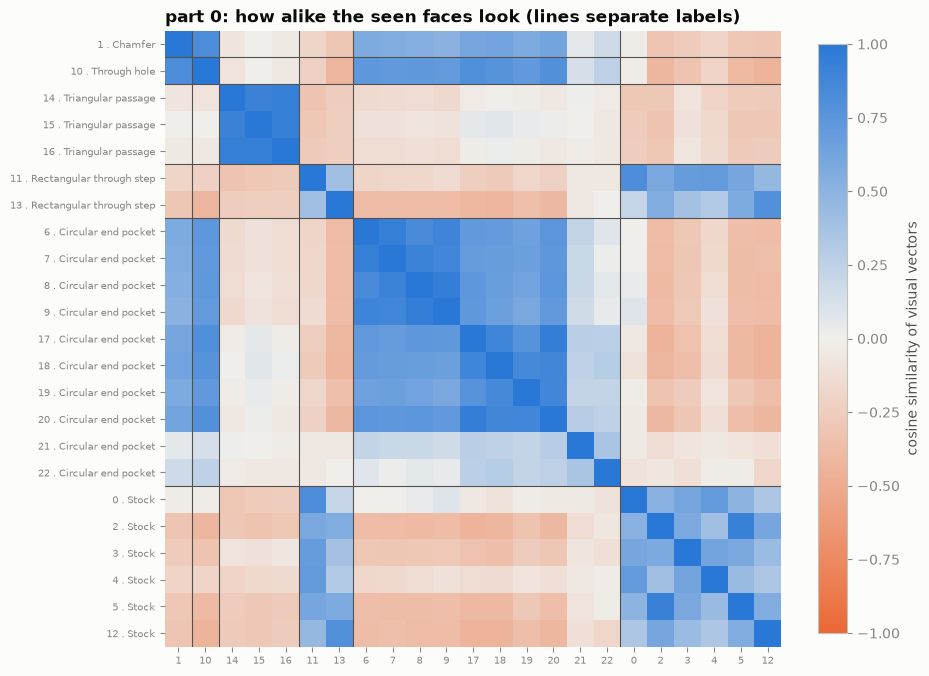

23 of 23 faces are seen by some view; 0 are hidden and have no visual vector


In [8]:
seen = (g.v[:, -1] > 0).numpy()
idx = [i for i in np.argsort(g.y.numpy(), kind="stable") if seen[i]]
v = g.v[idx, :-1]
v = v / v.norm(dim=1, keepdim=True)
sim = (v @ v.T).numpy()

diverging = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(sim, cmap=diverging, vmin=-1, vmax=1)
ticks = [f"{i} . {short_label(g.y[i])}" for i in idx]
ax.set_xticks(range(len(idx)), [str(i) for i in idx], fontsize=7)
ax.set_yticks(range(len(idx)), ticks, fontsize=7)
labels_sorted = [int(g.y[i]) for i in idx]
for b in [n for n in range(1, len(idx)) if labels_sorted[n] != labels_sorted[n - 1]]:
    ax.axhline(b - 0.5, color=INK2, linewidth=0.8)
    ax.axvline(b - 0.5, color=INK2, linewidth=0.8)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="cosine similarity of visual vectors")
ax.set_title(f"part {PART}: how alike the seen faces look (lines separate labels)")
plt.show()
print(f"{int(seen.sum())} of {g.num_nodes} faces are seen by some view; "
      f"{g.num_nodes - int(seen.sum())} are hidden and have no visual vector")

## 7. How many faces can the pictures see?

Over all 1500 test parts: the share of faces of each class that **at least one** of the 14 views sees.
A face no view sees gets zeros, so the 2D-only model knows nothing about it.
Version 1 had only 7 views (6 straight + 1 iso) and saw about 70% of faces: from straight views, pocket and hole walls are seen edge-on.
The 8 corner views look into them at an angle.

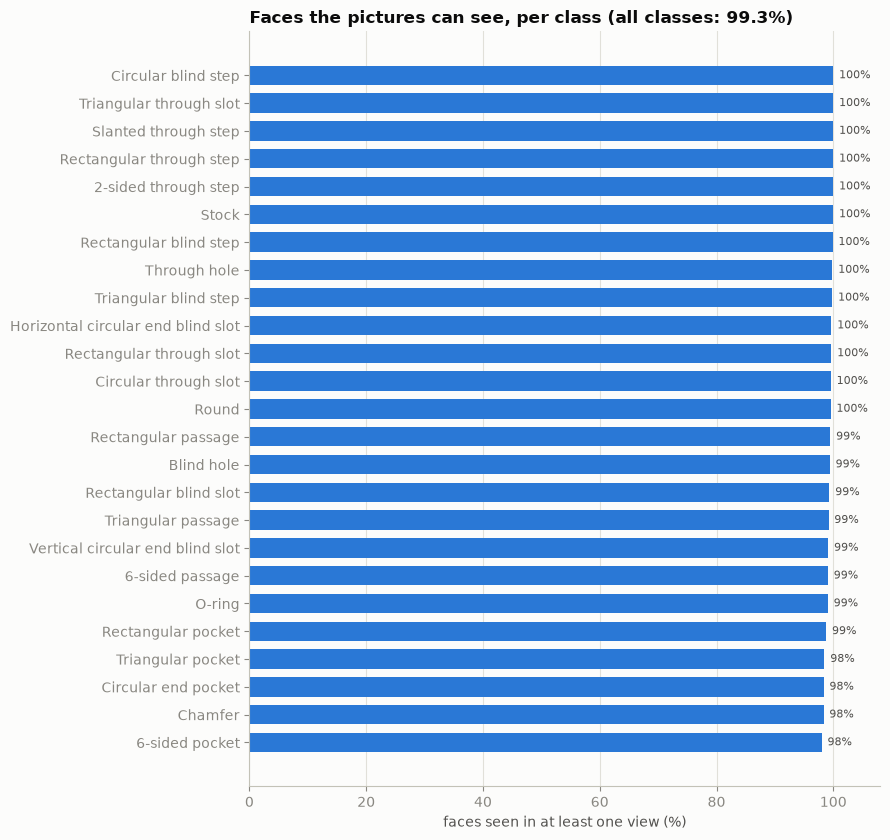

In [9]:
y_all = torch.cat([t.y for t in test_graphs])
seen_all = torch.cat([t.v[:, -1] for t in test_graphs]) > 0
share = np.array([100 * seen_all[y_all == c].float().mean().item() for c in range(K)])
order = np.argsort(share)

fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(range(K), share[order], color=HIGHLIGHT, height=0.7)
ax.set_yticks(range(K), [LABELS[c] for c in order])
for yi, s in enumerate(share[order]):
    ax.text(s + 1, yi, f"{s:.0f}%", va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 108)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("faces seen in at least one view (%)")
ax.set_title(f"Faces the pictures can see, per class (all classes: {100 * seen_all.float().mean():.1f}%)")
fig.tight_layout()
plt.show()

## 8. Training curves (step 6)

Saved by `train_fused.py`: for each model, after every epoch,

- **training loss** (left): how wrong the model is on the 6000 **training** parts (weighted cross-entropy; lower = fits them better). Drawn on a log scale so the small values stay readable.
- **validation accuracy** (right): % of faces right on 1000 parts it never trains on. The dot marks the best epoch of the average curve.

Each model was trained 3 times with different random seeds: **thin lines are the single runs, the thick line is their average.**
The spread between thin lines shows how much is just luck of the starting weights.

**How to read it:** if training loss keeps falling but validation accuracy stops rising or drops, the model is **memorising** the training parts instead of learning general rules (overfitting).

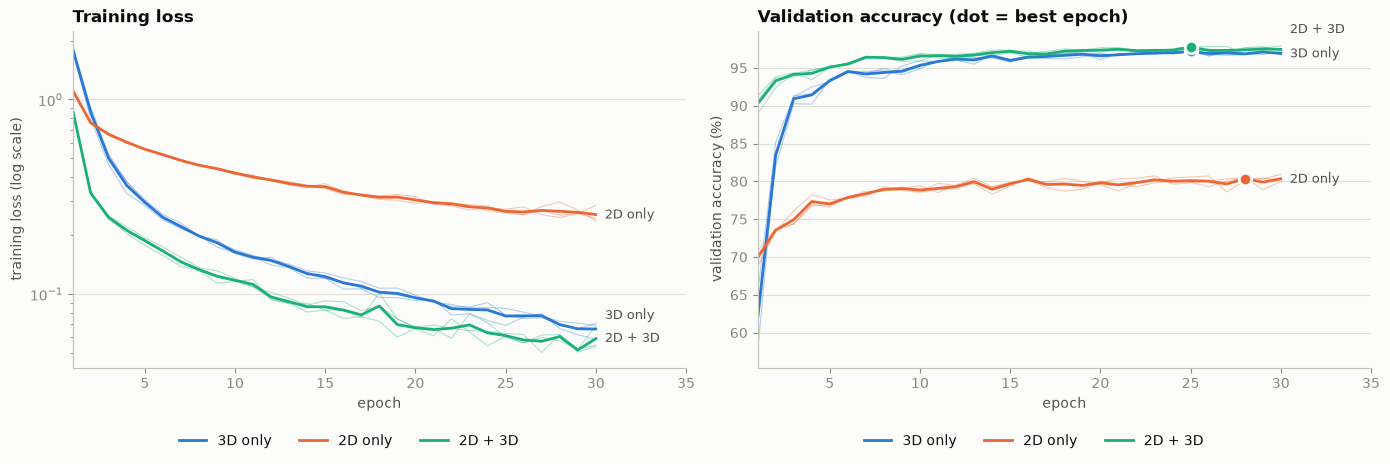

model          last train loss    best val acc (per run)
3D only                 0.0661            97.31 +- 0.07%
2D only                 0.2564            80.72 +- 0.15%
2D + 3D                 0.0590            97.85 +- 0.05%


In [10]:
def end_labels(ax, x, ys, texts, log=False):
    """Name each line at its right end, nudged apart so the names don't overlap."""
    lo, hi = ax.get_ylim()
    t = np.log10 if log else (lambda a: np.asarray(a, float))
    vals, gap = t(np.array(ys)), 0.07 * (t(hi) - t(lo))
    pos = vals.copy()
    order = np.argsort(vals)
    for a, b in zip(order, order[1:]):
        pos[b] = max(pos[b], pos[a] + gap)
    for p, text in zip(pos, texts):
        ax.text(x, 10 ** p if log else p, text, va="center", fontsize=9, color=INK2)


ep = np.arange(1, results["epochs"] + 1)
loss = {n: np.array([run["history"][n]["train_loss"] for run in RUNS]) for n in MODELS}       # (runs, epochs)
vacc = {n: 100 * np.array([run["history"][n]["val_acc"] for run in RUNS]) for n in MODELS}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for name in MODELS:
    for i in range(len(RUNS)):
        ax1.plot(ep, loss[name][i], color=COLOUR[name], linewidth=0.8, alpha=0.35)
        ax2.plot(ep, vacc[name][i], color=COLOUR[name], linewidth=0.8, alpha=0.35)
    ax1.plot(ep, loss[name].mean(0), color=COLOUR[name], label=SHORT[name])
    mean_acc = vacc[name].mean(0)
    ax2.plot(ep, mean_acc, color=COLOUR[name], label=SHORT[name])
    b = int(mean_acc.argmax())
    ax2.plot(ep[b], mean_acc[b], "o", color=COLOUR[name], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)

ax1.set_yscale("log")
ax1.set(xlabel="epoch", ylabel="training loss (log scale)", title="Training loss")
ax2.set(xlabel="epoch", ylabel="validation accuracy (%)", title="Validation accuracy (dot = best epoch)")
for ax in (ax1, ax2):
    ax.set_xlim(1, ep[-1] + 5)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.45, -0.16))
end_labels(ax1, ep[-1] + 0.5, [loss[n].mean(0)[-1] for n in MODELS], [SHORT[n] for n in MODELS], log=True)
end_labels(ax2, ep[-1] + 0.5, [vacc[n].mean(0)[-1] for n in MODELS], [SHORT[n] for n in MODELS])
fig.tight_layout()
plt.show()

print(f"{'model':<12}{'last train loss':>18}{'best val acc (per run)':>26}")
for name in MODELS:
    best = vacc[name].max(1)
    print(f"{SHORT[name]:<12}{loss[name][:, -1].mean():>18.4f}{best.mean():>17.2f} +- {best.std():.2f}%")

## 9. Test results (step 7)

1500 parts no model has seen, 44,631 faces. Each run of each model is tested once, with the weights from its best validation epoch.
Bars show the **average of the 3 runs**; the black line on each bar spans the lowest to the highest run.

- **Accuracy**: % of faces labelled right. Dominated by common classes (Stock is about 1 in 4 faces).
- **Mean IoU**: computed per class, then averaged, so every class counts the same. Harsher on rare classes.

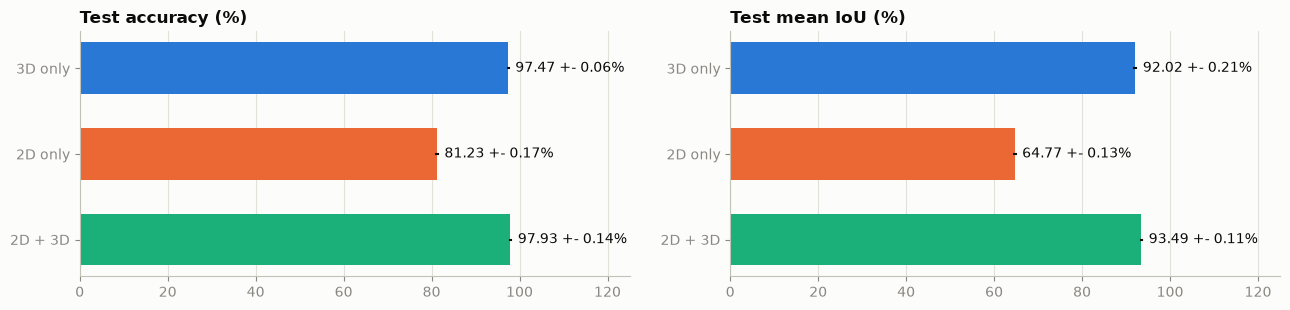

In [11]:
scores = {"Test accuracy (%)": {n: np.array([100 * accuracy(run["cm"][n]) for run in RUNS]) for n in MODELS},
          "Test mean IoU (%)": {n: np.array([100 * mean_iou(run["cm"][n]) for run in RUNS]) for n in MODELS}}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, (title, per_model) in zip(axes, scores.items()):
    ax.barh(range(3), [per_model[n].mean() for n in MODELS], color=[COLOUR[n] for n in MODELS], height=0.6)
    for yi, n in enumerate(MODELS):
        ax.plot([per_model[n].min(), per_model[n].max()], [yi, yi], color=INK, linewidth=1.5)
        ax.text(per_model[n].max() + 1.5, yi, f"{per_model[n].mean():.2f} +- {per_model[n].std():.2f}%",
                va="center", color=INK)
    ax.set_yticks(range(3), [SHORT[n] for n in MODELS])
    ax.invert_yaxis()
    ax.set_xlim(0, 125)
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_title(title)
fig.tight_layout()
plt.show()

## 10. Accuracy per class

IoU of every class, for each model (average of the 3 runs). Classes are sorted by the 3D-only result, weakest at the top.
Look for classes where the orange (2D only) bar is long: those are features the pictures recognise well on their own.

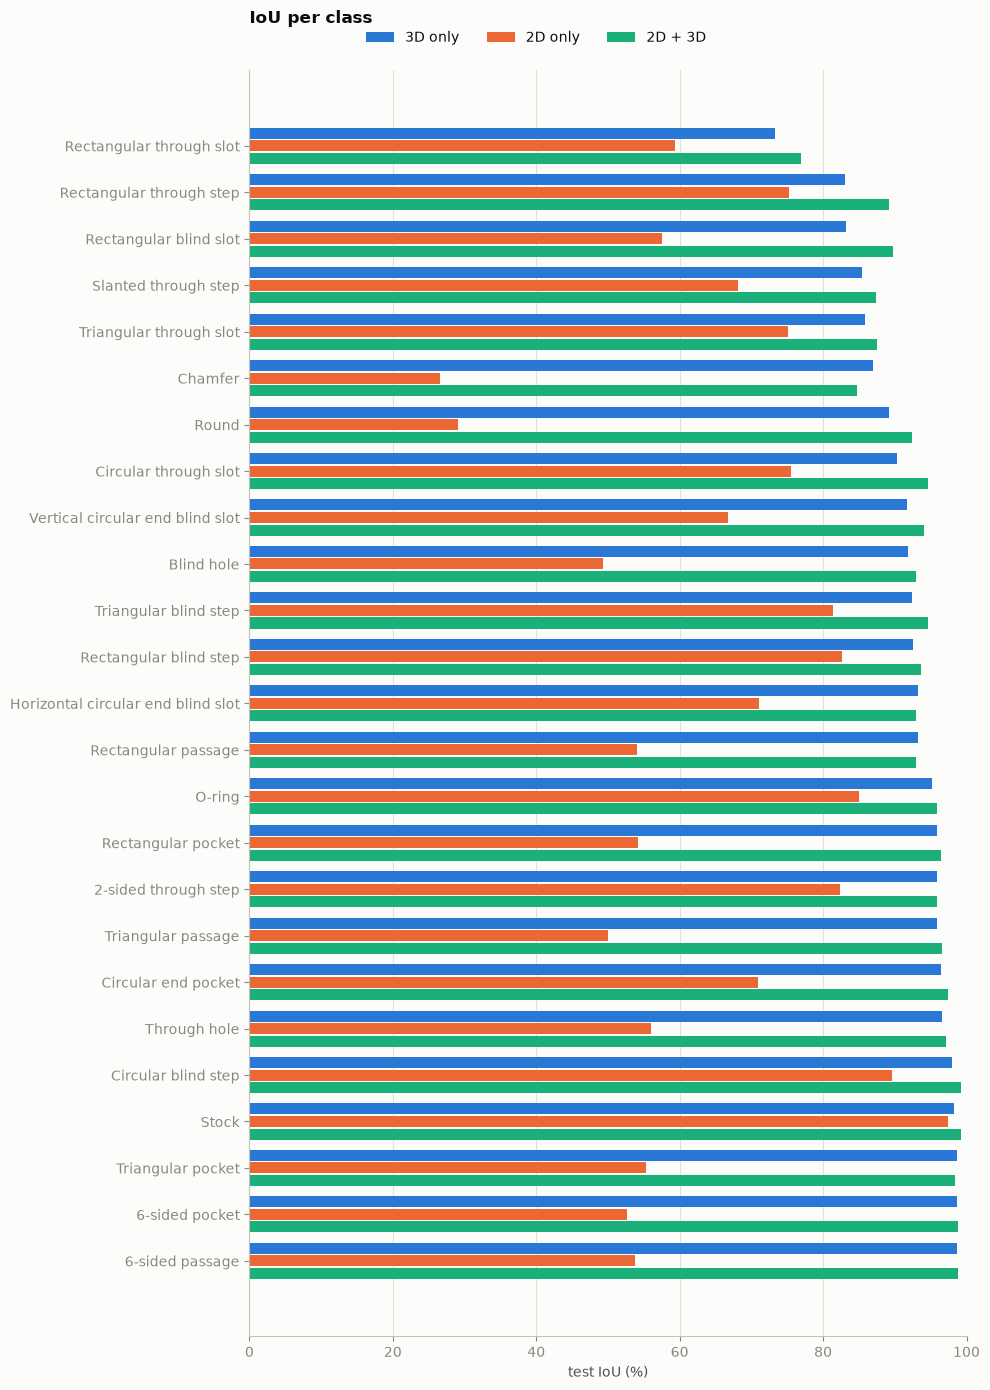

In [12]:
def class_iou(cm):
    tp = cm.diag().float()
    union = cm.sum(0).float() + cm.sum(1).float() - tp
    return (100 * tp / union.clamp(min=1)).numpy()


ious = {n: np.mean([class_iou(run["cm"][n]) for run in RUNS], axis=0) for n in MODELS}
order = np.argsort(ious[MODELS[0]])
h = 0.27
fig, ax = plt.subplots(figsize=(10, 14))
for j, name in enumerate(MODELS):
    ax.barh(np.arange(K) + (j - 1) * h, ious[name][order], height=h * 0.88, color=COLOUR[name], label=SHORT[name])
ax.set_yticks(np.arange(K), [LABELS[c] for c in order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("test IoU (%)")
ax.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.4, 1.01))
ax.set_title("IoU per class", pad=34)
fig.tight_layout()
plt.show()

## 11. Seen vs hidden faces

We run the three saved models (from run 1) over the test parts again and split the faces in two groups:
faces **seen** in at least one view, and faces **hidden** in every view (their visual vector is zeros).

The 2D-only model has nothing to go on for hidden faces, so this shows how much of its gap comes from what the cameras cannot see.

Also compare **3D only vs 2D + 3D on the seen faces**: that is where the visual numbers actually reach the model, so any gain or loss from fusion shows up there.

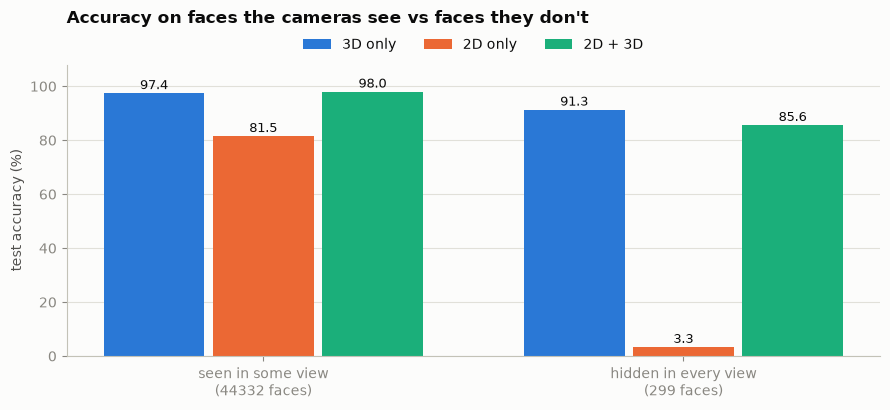

In [13]:
n_geo, n_edge, n_vis = g.x.shape[1], g.edge_attr.shape[1], g.v.shape[1]
models = {}
for name in MODELS:
    m = build_model(name, n_geo, n_vis, n_edge, K)
    m.load_state_dict(RUNS[0]["state"][name])
    models[name] = m.to(device).eval()

preds = {n: [] for n in MODELS}
with torch.no_grad():
    for batch in DataLoader(test_graphs, batch_size=64):
        batch = batch.to(device)
        for name, m in models.items():
            preds[name].append(m(batch).argmax(dim=1).cpu())
preds = {n: torch.cat(p) for n, p in preds.items()}

groups = {f"seen in some view\n({int(seen_all.sum())} faces)": seen_all,
          f"hidden in every view\n({int((~seen_all).sum())} faces)": ~seen_all}
fig, ax = plt.subplots(figsize=(9, 4.2))
for j, name in enumerate(MODELS):
    vals = [100 * (preds[name][sel] == y_all[sel]).float().mean().item() for sel in groups.values()]
    xs = np.arange(len(groups)) + (j - 1) * 0.26
    ax.bar(xs, vals, width=0.24, color=COLOUR[name], label=SHORT[name])
    for x, val in zip(xs, vals):
        ax.text(x, val + 1.5, f"{val:.1f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(len(groups)), list(groups))
ax.set_ylim(0, 108)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_ylabel("test accuracy (%)")
ax.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
ax.set_title("Accuracy on faces the cameras see vs faces they don't", pad=30)
fig.tight_layout()
plt.show()

## 12. Part viewer: right and wrong faces, per model

Back to our part. Each face in the iso view is coloured **green if that model labelled it right** and **red if wrong**, with its node number.
The table below lists every face, including the hidden ones the picture cannot show.

Change `PART` in section 2 and re-run from there to look at another part. Change `VIEW` to any name in `list(VIEWS)` (for example `"top"` or `"back-left-top"`).

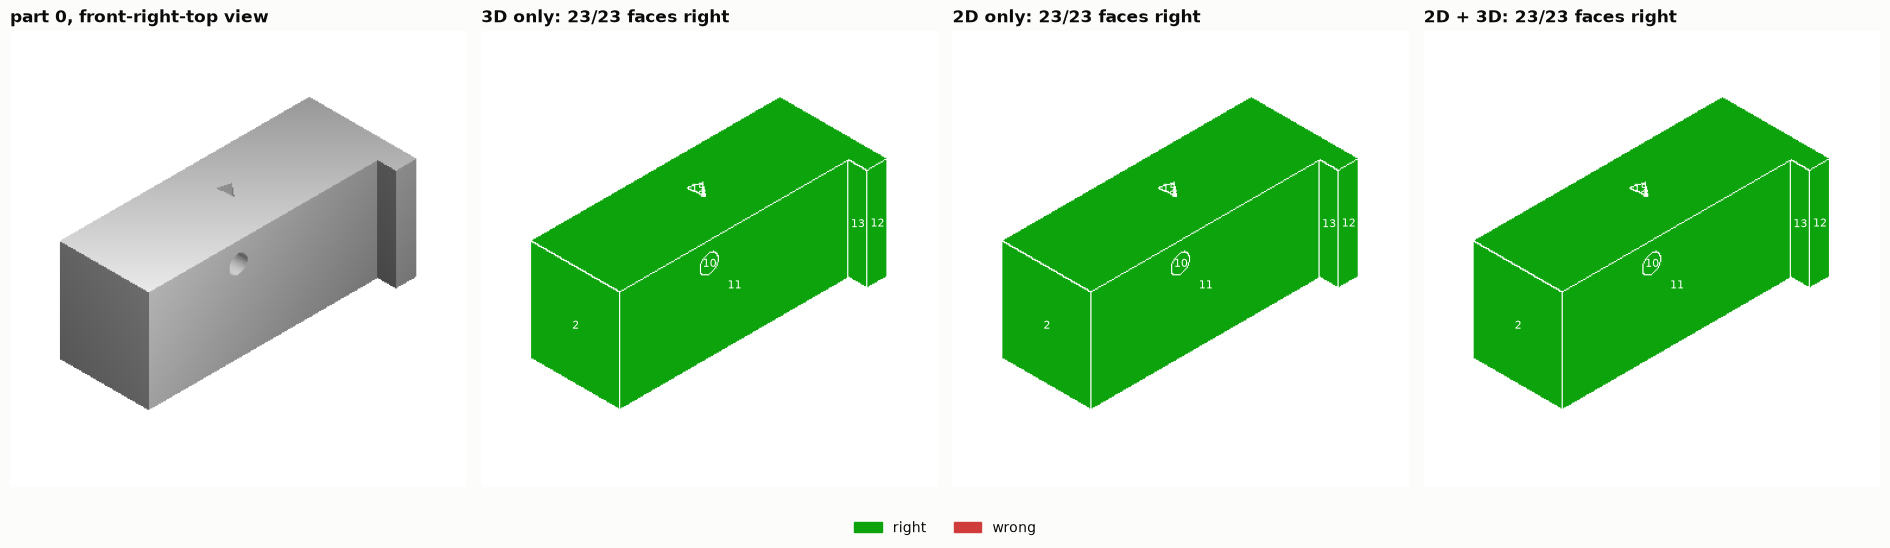

node  seen true label                3D only                   2D only                   2D + 3D                   
   0  yes  Stock                     ok Stock                  ok Stock                  ok Stock                  
   1  yes  Chamfer                   ok Chamfer                ok Chamfer                ok Chamfer                
   2  yes  Stock                     ok Stock                  ok Stock                  ok Stock                  
   3  yes  Stock                     ok Stock                  ok Stock                  ok Stock                  
   4  yes  Stock                     ok Stock                  ok Stock                  ok Stock                  
   5  yes  Stock                     ok Stock                  ok Stock                  ok Stock                  
   6  yes  Circular end pocket       ok Circular end pocket    ok Circular end pocket    ok Circular end pocket    
   7  yes  Circular end pocket       ok Circular end pocket    ok Circul

In [14]:
VIEW = ISO
j = names.index(VIEW)
fid = r["face_id"][j]
with torch.no_grad():
    part_pred = {n: m(g.clone().to(device)).argmax(dim=1).cpu() for n, m in models.items()}

border = np.zeros(fid.shape, bool)
border[:-1] |= fid[:-1] != fid[1:]
border[:, :-1] |= fid[:, :-1] != fid[:, 1:]
border &= fid > 0

fig, axes = plt.subplots(1, 4, figsize=(19, 5.4))
axes[0].imshow(r["shaded"][j])
axes[0].set_title(f"part {PART}, {VIEW} view")
for ax, name in zip(axes[1:], MODELS):
    right = (part_pred[name] == g.y).numpy()
    img = np.full((*fid.shape, 3), 255, np.uint8)
    for k in visible_faces(fid):
        img[fid == k] = (12, 163, 12) if right[k - 1] else (208, 59, 59)
    img[border] = 255                                    # white line where one face meets another
    ax.imshow(img)
    for k in visible_faces(fid):
        ys, xs = np.nonzero(fid == k)
        if len(xs) > 60:
            ax.text(xs.mean(), ys.mean(), str(k - 1), fontsize=8, ha="center", va="center", color="#ffffff")
    ax.set_title(f"{SHORT[name]}: {int(right.sum())}/{g.num_nodes} faces right")
no_axes(axes)
fig.legend(handles=[Patch(color=GOOD, label="right"), Patch(color=BAD, label="wrong")],
           loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

part_seen = (g.v[:, -1] > 0).numpy()
print(f"{'node':>4}  {'seen':<5}{'true label':<26}" + "".join(f"{SHORT[n]:<26}" for n in MODELS))
for i in range(g.num_nodes):
    row = f"{i:>4}  {'yes' if part_seen[i] else 'no':<5}{short_label(g.y[i]):<26}"
    for n in MODELS:
        p = int(part_pred[n][i])
        row += f"{('ok ' if p == g.y[i] else 'X  ') + short_label(p, 22):<26}"
    print(row)

## 13. Before vs after the fixes (version 1 -> version 2)

Version 1 (the first run) had four known problems. Version 2 changes:

| Problem in version 1 | Change in version 2 |
|---|---|
| only ~70% of faces seen by any view | 14 views instead of 7 (8 corner views instead of 1 iso) |
| tiny faces in the same 16 x 16 square got identical vectors | average over 4 x 4 pixel cells (square vectors smoothly enlarged) |
| fused model memorised: 769 visual numbers next to 15 geometry numbers | visual vector squeezed to 32 numbers first, 30% dropout on it while training |
| one run only, random start weights not tied to the seed | 3 runs per model, seed set right before each model is created |

The 3D-only model gets **exactly the same input** in both versions, so its change is only training luck. Use it as a ruler for how big a
difference must be before it means something.

model        v1 accuracy        v2 accuracy (3 runs)   v1 mean IoU        v2 mean IoU (3 runs)
3D only           97.32%              97.47 +- 0.06%        91.24%              92.02 +- 0.21%
2D only           62.98%              81.23 +- 0.17%        47.89%              64.77 +- 0.13%
2D + 3D           95.91%              97.93 +- 0.14%        87.61%              93.49 +- 0.11%


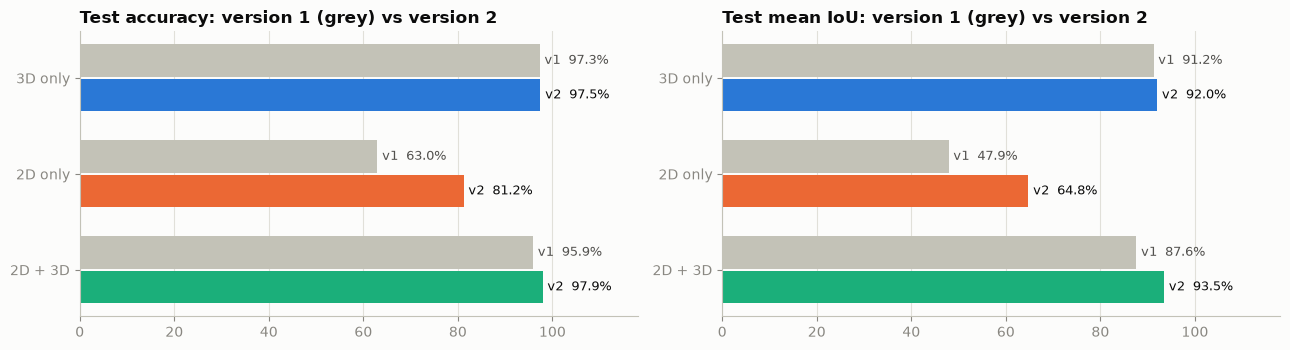

In [15]:
old_path = os.path.join(HERE, "data", "fused_results_v1.pt")
if not os.path.exists(old_path):
    print("no version 1 results saved (data/fused_results_v1.pt); nothing to compare")
else:
    old = torch.load(old_path, weights_only=False)
    old_cm = old["cm"] if "cm" in old else old["runs"][0]["cm"]
    table = {"accuracy": accuracy, "mean IoU": mean_iou}
    print(f"{'model':<10}" + "".join(f"{'v1 ' + t:>14}{'v2 ' + t + ' (3 runs)':>28}" for t in table))
    for n in MODELS:
        row = f"{SHORT[n]:<10}"
        for f in table.values():
            new = np.array([100 * f(run["cm"][n]) for run in RUNS])
            row += f"{100 * f(old_cm[n]):>13.2f}%{new.mean():>19.2f} +- {new.std():.2f}%"
        print(row)

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    for ax, (title, f) in zip(axes, table.items()):
        for yi, n in enumerate(MODELS):
            v1 = 100 * f(old_cm[n])
            v2 = np.mean([100 * f(run["cm"][n]) for run in RUNS])
            ax.barh(yi - 0.18, v1, height=0.34, color=AXIS)
            ax.barh(yi + 0.18, v2, height=0.34, color=COLOUR[n])
            ax.text(v1 + 1, yi - 0.18, f"v1  {v1:.1f}%", va="center", fontsize=9, color=INK2)
            ax.text(v2 + 1, yi + 0.18, f"v2  {v2:.1f}%", va="center", fontsize=9, color=INK)
        ax.set_yticks(range(3), [SHORT[n] for n in MODELS])
        ax.invert_yaxis()
        ax.set_xlim(0, 118)
        ax.xaxis.grid(True)
        ax.set_axisbelow(True)
        ax.set_title(f"Test {title}: version 1 (grey) vs version 2")
    fig.tight_layout()
    plt.show()